# 02 ? Events: EDA, cleaning and merge

Consolidated from the original `sect2` notebooks. The executable pipeline lives in `src/` (`python -m src.pipeline`); these notebooks document the exploration, the cleaning decisions and the device/event merge.


---

## Part 1 ? Preliminary EDA

# Preliminary Exploratory Data Analysis

Auto-generated overview of a CSV dataset. Drop your file in `data/raw/` and run all cells.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline
print("Libraries loaded correctly")


Libraries loaded correctly


## 1. Data Loading

Detects and loads the CSVs found in `data/raw/`.

In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("events")
print(f"Loading: {file_path.name}")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")


Loading: events-1681209680.csv


Shape: 124,969 rows x 30 columns


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124969 entries, 0 to 124968
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   id                      124969 non-null  int64 
 1   action                  62481 non-null   object
 2   action_classification   52950 non-null   object
 3   action_level            2456 non-null    object
 4   action_summary          29105 non-null   object
 5   authorities_link        124887 non-null  object
 6   country                 124968 non-null  object
 7   create_date             5201 non-null    object
 8   data_notes              57928 non-null   object
 9   date                    48763 non-null   object
 10  date_initiated_by_firm  55658 non-null   object
 11  date_posted             44187 non-null   object
 12  date_terminated         31487 non-null   object
 13  date_updated            231 non-null     object
 14  determined_cause        35818 non-nu

In [4]:
df.head(10)


,id,action,action_classification,action_level,action_summary,authorities_link,country,create_date,data_notes,date,...,status,target_audience,type,uid,uid_hash,url,slug,device_id,created_at,updated_at
0,1,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-04-04,...,NaN,NaN,Field Safety Notice,2016/294 & FA24MAR2016,41570514,https://web.archive.org/web/20170817053524/htt...,tur-cell-dyn-emerald-cleanser,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-09-20,...,NaN,NaN,Field Safety Notice,2016/844 & FSCA2016-02,415f04f4,https://web.archive.org/web/20170817104322/htt...,tur-tecnis-monofocal-1-piece-tecnis-1-piece-io...,2,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
2,3,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-05-09,...,NaN,NaN,Field Safety Notice,2016/437 & 2016018,2caa03df,https://web.archive.org/web/20170818050616/htt...,tur-centurion-fms-package-for-centurion-vision...,3,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
3,4,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-12-19,...,NaN,NaN,Field Safety Notice,2016/1188 & 002/AS60130/17.00,666f0625,https://web.archive.org/web/20171014025042/htt...,tur-focusforce-intraocular-foldable-lenses,4,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
4,5,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2017-02-20,...,NaN,NaN,Field Safety Notice,2017/242 & 02R06-21 / 02R06-31,6a8d063c,https://web.archive.org/web/20171014000531/htt...,tur-cholesterol-hdl-direct,5,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
5,6,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-08,...,NaN,NaN,Field Safety Notice,2016/117 & Afc-fsca-2015-001,6d9c06ff,https://web.archive.org/web/20170817123339/htt...,tur-blood-glucose-test-strip,6,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
6,7,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-26,...,NaN,NaN,Field Safety Notice,2016/70 & EIF1507-34,291a03fb,https://web.archive.org/web/20170817132536/htt...,tur-super-arrow-flex-r-percutaneous-sheath-int...,7,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
7,8,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-08-16,...,NaN,NaN,Field Safety Notice,2016/156 & EIF1507-33,3b7804af,https://web.archive.org/web/20170815184818/htt...,tur-catheter-introducer,8,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
8,9,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-04-28,...,NaN,NaN,Field Safety Notice,2016/156 & EIF1507-33,3b7804af,https://web.archive.org/web/20170815184818/htt...,tur-catheter-introducer-3b7804af,8,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
9,10,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-09,...,NaN,NaN,Field Safety Notice,2016/124 & ASPENR1,2ee10470,https://web.archive.org/web/20170817112452/htt...,tur-22g-bi-manual-aspiration-pull-handle-0-38m...,9,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


## 2. Column Overview

Data types, non-null counts, and memory usage.

In [5]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124969 entries, 0 to 124968
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   id                      124969 non-null  int64 
 1   action                  62481 non-null   object
 2   action_classification   52950 non-null   object
 3   action_level            2456 non-null    object
 4   action_summary          29105 non-null   object
 5   authorities_link        124887 non-null  object
 6   country                 124968 non-null  object
 7   create_date             5201 non-null    object
 8   data_notes              57928 non-null   object
 9   date                    48763 non-null   object
 10  date_initiated_by_firm  55658 non-null   object
 11  date_posted             44187 non-null   object
 12  date_terminated         31487 non-null   object
 13  date_updated            231 non-null     object
 14  determined_cause        35818 non-nu

In [6]:
with pd.option_context(
    'display.width', 1000,       
    'display.max_colwidth', None  
):
    print(df['documents'])

0                                                                                                                                                                                                                                                                                               NaN
1                                                                                                                                                                                                                                                                                               NaN
2                                                                                                                                                                                                                                                                                               NaN
3                                                                                                                           

The links won´t work...probably due to a lack of DNS knowledge, so the column will be droped.

In [7]:
with pd.option_context(
    'display.width', 1000,        # Set maximum width of output
    'display.max_colwidth', None  # Allow columns to expand fully
):
    print(df['action_summary'])

0         Recall
1         Recall
2         Recall
3         Recall
4         Recall
           ...  
124964       NaN
124965       NaN
124966       NaN
124967       NaN
124968       NaN
Name: action_summary, Length: 124969, dtype: object

In [8]:
df['action_summary'].unique()

array(['Recall', 'Software Update', 'Information Note', ...,
       'Hazard Alert', 'Product Defect Correction',
       'Product Defect Alert'], shape=(17593,), dtype=object)

In [9]:
df['action_summary'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 124969 entries, 0 to 124968
Series name: action_summary
Non-Null Count  Dtype 
--------------  ----- 
29105 non-null  object
dtypes: object(1)
memory usage: 976.4+ KB


In [10]:
dtype_counts = df.dtypes.value_counts()
print("Column type distribution:")
for dtype, count in dtype_counts.items():
    print(f"  {dtype.name}: {count} columns")


Column type distribution:
  object: 28 columns
  int64: 2 columns


## 3. Missing Values Analysis

In [11]:
print(f"{df.isna().sum().sum()}")


1576689


In [12]:
df['url'].head(5)

0    https://web.archive.org/web/20170817053524/htt...
1    https://web.archive.org/web/20170817104322/htt...
2    https://web.archive.org/web/20170818050616/htt...
3    https://web.archive.org/web/20171014025042/htt...
4    https://web.archive.org/web/20171014000531/htt...
Name: url, dtype: object

Got a http 302 response in the urls, no updates so I will drop this column.

In [13]:
# Per-column nulls
missing_cols = pd.DataFrame({
    "Missing": df.isna().sum(),
    "%": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("Missing", ascending=False)

missing_cols = missing_cols[missing_cols["Missing"] > 0]
if missing_cols.empty:
    print("No missing values found.")
else:
    display(missing_cols)
    print(f"\nTotal missing values: {df.isna().sum().sum()}")


,Missing,%
date_updated,124738,99.82
target_audience,124529,99.65
action_level,122513,98.03
create_date,119768,95.84
action_summary,95864,76.71
date_terminated,93482,74.80
determined_cause,89151,71.34
status,88440,70.77
documents,83930,67.16
number,80958,64.78



Total missing values: 1576689


| More of 95% of nulls columns will be dropped. | Missing | % |
| --- | --- | --- |
| date_updated | 124738 | 99.82 |
| target_audience | 124529 | 99.65 |
| action_level | 122513 | 98.03 |
| create_date | 119768 | 95.84 |


In [14]:
# Per-row null distribution
nulls_per_row = df.isna().sum(axis=1)

print("Rows with nulls:")
for threshold in [1, 2, 5, 10, 20, 50]:
    count = (nulls_per_row >= threshold).sum()
    print(f"  ≥{threshold:>3} nulls: {count:>6,} rows ({count / len(df) * 100:>5.1f}%)")

print(f"\nNulls per row — distribution:")
dist = nulls_per_row.value_counts().sort_index()
display(dist.head(20).to_frame("# rows"))


Rows with nulls:
  ≥  1 nulls: 124,969 rows (100.0%)
  ≥  2 nulls: 124,969 rows (100.0%)
  ≥  5 nulls: 124,969 rows (100.0%)
  ≥ 10 nulls: 89,152 rows ( 71.3%)
  ≥ 20 nulls:      4 rows (  0.0%)
  ≥ 50 nulls:      0 rows (  0.0%)

Nulls per row — distribution:


,# rows
7,29805
8,5917
9,95
10,93
11,2588
12,7468
13,6192
14,18277
15,26444
16,17816


In [15]:
# Column drop recommendations (>40% nulls)
null_pct = df.isna().mean() * 100
rec_df = pd.DataFrame({
    "Null %": null_pct.round(2),
    "Recommendation": null_pct.apply(
        lambda p: "DROP (>40%)" if p > 40 else "KEEP"
    )
}).sort_values("Null %", ascending=False)

to_drop = rec_df[rec_df["Recommendation"] == "DROP (>40%)"]
if not to_drop.empty:
    print("=" * 55)
    print(f"  {len(to_drop)} column(s) with >40% nulls — recommended for removal")
    print("=" * 55)
    display(to_drop)
else:
    print("No columns exceed 40% nulls — none recommended for removal.")


  17 column(s) with >40% nulls — recommended for removal


,Null %,Recommendation
date_updated,99.82,DROP (>40%)
target_audience,99.65,DROP (>40%)
action_level,98.03,DROP (>40%)
create_date,95.84,DROP (>40%)
action_summary,76.71,DROP (>40%)
date_terminated,74.80,DROP (>40%)
determined_cause,71.34,DROP (>40%)
status,70.77,DROP (>40%)
documents,67.16,DROP (>40%)
number,64.78,DROP (>40%)


In [16]:
df['date_updated'].unique()

array([nan, '2019-03-04', '2017-08-24', '2019-02-08', '2019-01-29',
       '2018-07-06', '2016-05-11', '2018-07-27', '2014-11-19',
       '2016-07-28', '2019-01-14', '2014-12-03', '2018-09-20',
       '2012-02-07', '2016-09-13', '2018-05-30', '2018-12-21',
       '2013-10-22', '2016-07-03', '2018-06-26', '2017-01-20',
       '2016-11-04', '2017-03-03', '2014-04-24', '2015-01-31',
       '2016-07-26', '2013-09-09', '2017-08-15', '2015-07-07',
       '2018-04-02', '2017-05-24', '2018-11-13', '2017-02-14',
       '2017-05-18', '2017-07-26', '2015-05-26', '2019-02-05',
       '2017-07-04', '2016-12-14', '2014-05-09', '2014-12-02',
       '2018-03-19', '2017-10-17', '2014-03-26', '2015-06-30',
       '2019-03-08', '2019-01-03', '2014-07-14', '2015-03-04',
       '2018-12-27', '2013-12-03', '2019-01-28', '2015-10-14',
       '2017-03-30', '2015-12-30', '2017-02-27', '2013-04-29',
       '2012-12-13', '2014-07-25', '2018-09-26', '2017-06-08',
       '2018-11-20', '2015-08-20', '2018-04-12', '

In [17]:
df['action_summary'].unique()

array(['Recall', 'Software Update', 'Information Note', ...,
       'Hazard Alert', 'Product Defect Correction',
       'Product Defect Alert'], shape=(17593,), dtype=object)

For this exploratory analysis I won´t use  the column 'action_summary', so I will drop it.

In [18]:
(df['created_at']==df['updated_at']).sum() / len(df)

np.float64(1.0)

In [19]:
columnas = pd.Series(df.columns.values)

In [20]:
columnas

0                         id
1                     action
2      action_classification
3               action_level
4             action_summary
5           authorities_link
6                    country
7                create_date
8                 data_notes
9                       date
10    date_initiated_by_firm
11               date_posted
12           date_terminated
13              date_updated
14          determined_cause
15                 documents
16                icij_notes
17                    number
18                    reason
19                    source
20                    status
21           target_audience
22                      type
23                       uid
24                  uid_hash
25                       url
26                      slug
27                 device_id
28                created_at
29                updated_at
dtype: object

The columns created_at and updated_at are the same, gonna drop the second one.

In [21]:
df.head(2)

,id,action,action_classification,action_level,action_summary,authorities_link,country,create_date,data_notes,date,...,status,target_audience,type,uid,uid_hash,url,slug,device_id,created_at,updated_at
0,1,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-04-04,...,NaN,NaN,Field Safety Notice,2016/294 & FA24MAR2016,41570514,https://web.archive.org/web/20170817053524/htt...,tur-cell-dyn-emerald-cleanser,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-09-20,...,NaN,NaN,Field Safety Notice,2016/844 & FSCA2016-02,415f04f4,https://web.archive.org/web/20170817104322/htt...,tur-tecnis-monofocal-1-piece-tecnis-1-piece-io...,2,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


In [22]:
(df['data_notes'].isna().sum()/len(df))*100

np.float64(53.64610423384999)

In [23]:
(df['action_summary'].isna().sum()/len(df))*100

np.float64(76.71022413558562)

In [24]:
(df['action_classification'].isna().sum()/len(df))*100

np.float64(57.629492114044275)

In [25]:
df['action_classification'].unique()

array([nan, 'Class 2', 'Class 3', 'Class 1', 'Unclassified Correction',
       'Class I', 'Voluntary recall', 'II', 'III', 'I', 'Class II',
       'Class III'], dtype=object)

In [26]:
test = df.copy()

In [27]:
test.drop(columns='url', inplace=True)
test.drop(columns='updated_at', inplace=True)
test.drop(columns='target_audience', inplace=True)
test.drop(columns='authorities_link', inplace=True)
test.drop(columns='data_notes', inplace=True)
test.drop(columns='date_posted', inplace=True)
test.drop(columns='date_terminated', inplace=True)
test.drop(columns='status', inplace=True)
test.drop(columns='date_updated', inplace=True)
test.drop(columns='action_level', inplace=True)
test.drop(columns='create_date', inplace=True)

In [28]:
columnsDroped = test.dropna(thresh=15).copy()

In [29]:
columnsDroped.shape

(39520, 19)

In [30]:
columnsDroped

,id,action,action_classification,action_summary,country,date,date_initiated_by_firm,determined_cause,documents,icij_notes,number,reason,source,type,uid,uid_hash,slug,device_id,created_at
13301,13302,Natus Medical has begun mailing the Urgent Re...,Class 2,NaN,USA,NaN,2014-11-19,Other,NaN,U.S. data is current through June 2018. All of...,Z-0847-2015,Replacement LED Board kit of Natus neoBLUE2 Ph...,U.S. Food and Drug Administration,Recall,69820,0333010a,usa-device-recall-natus-neoblue-2-phototherapy...,12530,2022-08-04 08:32:48 UTC
13302,13303,"Roche sent the ""Urgent Medical Device Correcti...",Class 2,NaN,USA,NaN,2014-11-20,Device Design,NaN,U.S. data is current through June 2018. All of...,Z-0890-2015,Roche Diabetes Care was informed by UnoMedical...,U.S. Food and Drug Administration,Recall,69821,0334010b,usa-device-recall-accuchek-tender-ii-infusion-set,12531,2022-08-04 08:32:48 UTC
13303,13304,"Roche sent the ""Urgent Medical Device Correcti...",Class 2,NaN,USA,NaN,2014-11-20,Device Design,NaN,U.S. data is current through June 2018. All of...,Z-0891-2015,Roche Diabetes Care was informed by UnoMedical...,U.S. Food and Drug Administration,Recall,69821,0334010b,usa-device-recall-accuchek-tender-ii-infusion-...,12532,2022-08-04 08:32:48 UTC
13304,13305,"Roche sent the ""Urgent Medical Device Correcti...",Class 2,NaN,USA,NaN,2014-11-20,Device Design,NaN,U.S. data is current through June 2018. All of...,Z-0892-2015,Roche Diabetes Care was informed by UnoMedical...,U.S. Food and Drug Administration,Recall,69821,0334010b,usa-device-recall-accuchek-tender-ii-infusion-...,12533,2022-08-04 08:32:48 UTC
13305,13306,"Roche sent the ""Urgent Medical Device Correcti...",Class 2,NaN,USA,NaN,2014-11-20,Device Design,NaN,U.S. data is current through June 2018. All of...,Z-0893-2015,Roche Diabetes Care was informed by UnoMedical...,U.S. Food and Drug Administration,Recall,69821,0334010b,usa-device-recall-accuchek-tender-ii-infusion-...,12534,2022-08-04 08:32:48 UTC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123195,123196,Getinge have developed a compressor with a hig...,Class II,Product Defect Correction,AUS,NaN,2018-07-06,NaN,NaN,Australian data is current through July 2018. ...,NaN,Getinge have identified an issue which may res...,"Department of Health, Therapeutic Goods Admini...",Recall,RC-2018-RN-00906-1,268703e5,aus-getinge-eds8-endoscope-drying-and-storage-...,116514,2022-08-04 10:48:36 UTC
123196,123197,Radiometer is advising that they are currently...,Class II,Product Defect Correction,AUS,NaN,2018-07-09,NaN,NaN,Australian data is current through July 2018. ...,NaN,Radiometer has recently become aware that the ...,"Department of Health, Therapeutic Goods Admini...",Recall,RC-2018-RN-00926-1,268f03e7,aus-radiometer-abl800-blood-gas-analysers-with...,116515,2022-08-04 10:48:36 UTC
123197,123198,Users are asked to:\n\nReview the customer let...,Class II,Product Defect Correction,AUS,NaN,2018-07-09,NaN,NaN,Australian data is current through July 2018. ...,NaN,The Perifix Catheter Connector is a connection...,"Department of Health, Therapeutic Goods Admini...",Recall,RC-2018-RN-00928-1,269503e9,aus-perifix-catheter-connector-perifix-complet...,116516,2022-08-04 10:48:37 UTC
123198,123199,Microport CRM is initiating a removal of the n...,Class I,Recall,AUS,NaN,2018-07-09,NaN,NaN,Australian data is current through July 2018. ...,NaN,On a subset of Platinium ICD and CRT-D devices...,"Department of Health, Therapeutic Goods Admini...",Recall,RC-2018-RN-00929-1,269803ea,aus-platinium-implantable-cardiac-defibrillato...,116517,2022-08-04 10:48:37 UTC


In [31]:
columnsDroped['date'].isna().sum()

np.int64(39373)

Won´t use this column, not enough data to traspass the umbral.

In [32]:
columnsDroped.drop(columns='date', inplace=True)

In [33]:
file_path2 = proc_dir / "devicesProcessed.csv"
if not file_path2.exists():
    raise FileNotFoundError(f"{'Ejecuta notebooks/01_devices.ipynb'}: {file_path2}")

print(f"Loading: {file_path2.name}")
df2 = pd.read_csv(file_path2, encoding="utf-8", low_memory=False)
print(f"Shape: {df2.shape[0]:,} rows x {df2.shape[1]:,} columns")


Loading: devicesProcessed.csv
Shape: 30,556 rows x 12 columns


In [34]:
columnsDroped.columns

Index(['id', 'action', 'action_classification', 'action_summary', 'country',
       'date_initiated_by_firm', 'determined_cause', 'documents', 'icij_notes',
       'number', 'reason', 'source', 'type', 'uid', 'uid_hash', 'slug',
       'device_id', 'created_at'],
      dtype='object')

In [35]:
df2.shape

(30556, 12)

In [36]:
df2.columns

Index(['id', 'classification', 'code', 'description', 'distributed_to',
       'implanted', 'name', 'quantity_in_commerce', 'risk_class', 'slug',
       'manufacturer_id', 'created_at'],
      dtype='object')

In [37]:
merged_df = columnsDroped.merge(df2, left_on='device_id', right_on='id', how='inner')

In [38]:
merged_df.shape

(32224, 30)

In [39]:
merged_df

,id_x,action,action_classification,action_summary,country,date_initiated_by_firm,determined_cause,documents,icij_notes,number,...,code,description,distributed_to,implanted,name,quantity_in_commerce,risk_class,slug_y,manufacturer_id,created_at_y
0,13302,Natus Medical has begun mailing the Urgent Re...,Class 2,NaN,USA,2014-11-19,Other,NaN,U.S. data is current through June 2018. All of...,Z-0847-2015,...,LBI,"Replacement LED PCB Kit, part number 001840, o...",worldwide,NO,Device Recall Natus neoBLUE 2 Phototherapy sy...,1907 total (1413 in US and 494 international),2,usa-general-hospital-and-personal-use-devices-...,4827,2022-08-04 08:32:48 UTC
1,13303,"Roche sent the ""Urgent Medical Device Correcti...",Class 2,NaN,USA,2014-11-20,Device Design,NaN,U.S. data is current through June 2018. All of...,Z-0890-2015,...,FPA,ACCU-CHEK Tender II 13/80 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,"Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,4828,2022-08-04 08:32:48 UTC
2,13304,"Roche sent the ""Urgent Medical Device Correcti...",Class 2,NaN,USA,2014-11-20,Device Design,NaN,U.S. data is current through June 2018. All of...,Z-0891-2015,...,FPA,ACCU-CHEK Tender II 13/110 10 + 10 pieces || P...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,"Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,4828,2022-08-04 08:32:48 UTC
3,13305,"Roche sent the ""Urgent Medical Device Correcti...",Class 2,NaN,USA,2014-11-20,Device Design,NaN,U.S. data is current through June 2018. All of...,Z-0892-2015,...,FPA,ACCU-CHEK Tender II 17/60 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,"Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,4828,2022-08-04 08:32:48 UTC
4,13306,"Roche sent the ""Urgent Medical Device Correcti...",Class 2,NaN,USA,2014-11-20,Device Design,NaN,U.S. data is current through June 2018. All of...,Z-0893-2015,...,FPA,ACCU-CHEK Tender II 17/80 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,"Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,4828,2022-08-04 08:32:48 UTC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32219,110411,Beckman Coulter sent an Urgent Product Correct...,Class 2,NaN,USA,2010-10-20,Other,NaN,U.S. data is current through June 2018. All of...,Z-1980-2011,...,GKZ,UniCel DxH 800 Floor Cabinet Part Number: 7233...,Worldwide Distribution - USA (nationwide) and ...,NO,UniCel DxH 800 Analyzer,422 units in total (175 in US),2,usa-hematology-and-pathology-devices-unicel-dx...,4892,2022-08-04 10:25:03 UTC
32220,110412,"On October 25, 2010, an Urgent Medical Device ...",Class 2,NaN,USA,2010-10-25,Nonconforming Material/Component,NaN,U.S. data is current through June 2018. All of...,Z-0071-2012,...,LPA,***REF #200***TAPSCOPE 550. Each pouch contain...,"Nationwide Distribution -- GA, OR, TX, CO, KY,...",NO,TAPSCOPE 550,567 total,3,usa-cardiovascular-devices-tapscope-550-dcd20e15,26448,2022-08-04 10:25:04 UTC
32221,110413,"The firm, MAKO, sent a ""RECALL NOTICE"" letter ...",Class 2,NaN,USA,2010-10-25,Nonconforming Material/Component,NaN,U.S. data is current through June 2018. All of...,Z-2232-2011,...,KQM,MAKO PN 204588 Camera || 204588 Label With Cam...,Nationwide distribution: NY only.,NO,MAKO PN 204588 Camera,1,1,usa-general-and-plastic-surgery-devices-mako-p...,5571,2022-08-04 10:25:04 UTC
32222,110414,"Newport Medical sent an PRODUCT NOTICE LETTER,...",Class 2,NaN,USA,2010-09-20,Other,NaN,U.S. data is current through June 2018. All of...,Z-2406-2011,...,CBK,"Newport HT70 Ventilator. Model #HT70, || The ...",Worldwide Distribution--USA (nationwide) inclu...,NO,Newport HT70 Ventilator,22 units total,2,usa-anesthesiology-devices-newport-ht70-ventil...,5645,2022-08-04 10:25:04 UTC


In [40]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32224 entries, 0 to 32223
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id_x                    32224 non-null  int64 
 1   action                  31952 non-null  object
 2   action_classification   32224 non-null  object
 3   action_summary          0 non-null      object
 4   country                 32224 non-null  object
 5   date_initiated_by_firm  31423 non-null  object
 6   determined_cause        32223 non-null  object
 7   documents               0 non-null      object
 8   icij_notes              32224 non-null  object
 9   number                  32224 non-null  object
 10  reason                  32216 non-null  object
 11  source                  32224 non-null  object
 12  type                    32224 non-null  object
 13  uid                     32224 non-null  object
 14  uid_hash                32224 non-null  object
 15  sl

## 4. Numerical Columns – Descriptive Statistics

In [41]:
num_cols = merged_df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = merged_df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")


Numerical columns (4): ['id_x', 'device_id', 'id_y', 'manufacturer_id']
Categorical / text columns (26): ['action', 'action_classification', 'action_summary', 'country', 'date_initiated_by_firm', 'determined_cause', 'documents', 'icij_notes', 'number', 'reason', 'source', 'type', 'uid', 'uid_hash', 'slug_x', 'created_at_x', 'classification', 'code', 'description', 'distributed_to', 'implanted', 'name', 'quantity_in_commerce', 'risk_class', 'slug_y', 'created_at_y']


The only numerical columns are id, and foreing key to another csv (devices).

## 5. Categorical Columns – Value Counts

In [42]:
for col in cat_cols[:10]:
    vc = merged_df[col].value_counts(dropna=False).head(15)
    print(f"\n--- {col} ({vc.sum():,} non-null / {merged_df[col].nunique():,} unique) ---")
    print(vc.to_string())



--- action (2,310 non-null / 13,581 unique) ---
action
NaN                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

## 6. Outlier Detection

Como en el notebook de devices, no procede outlier Detection en un dataset mayormente de texto.

## 7. Correlation Analysis

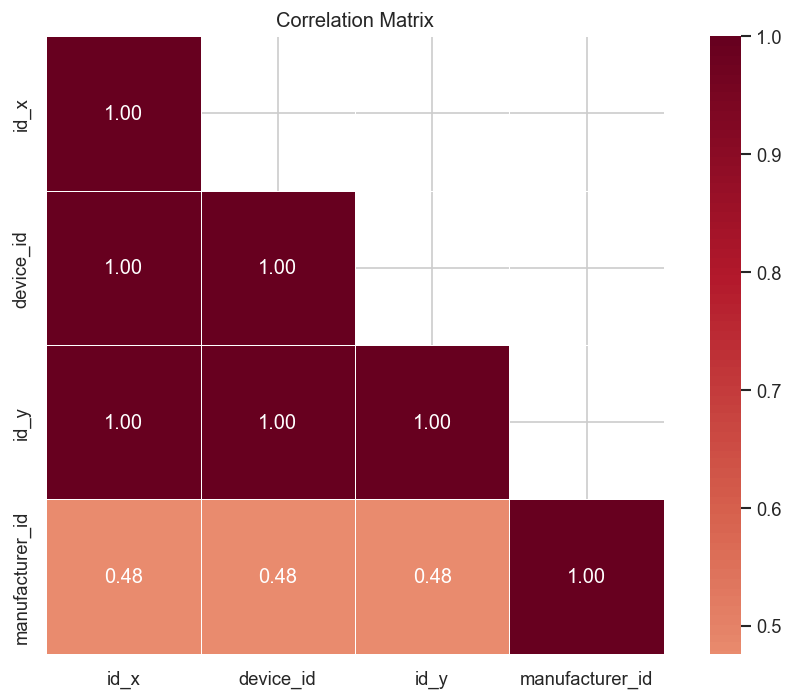

Top 10 strongest correlations:
  id_y  –  device_id: +1.0000
  id_x  –  device_id: +1.0000
  id_y  –  manufacturer_id: +0.4761
  id_x  –  manufacturer_id: +0.4760


In [43]:
if len(num_cols) >= 2:
    corr = merged_df[num_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    plt.figure(figsize=(max(8, len(num_cols) * 0.6), max(6, len(num_cols) * 0.5)))
    sns.heatmap(corr, mask=mask, annot=len(num_cols) <= 20,
                fmt=".2f", cmap="RdBu_r", center=0,
                square=True, linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    corr_unstacked = corr.unstack()
    corr_unstacked = corr_unstacked[
        corr_unstacked.index.get_level_values(0) !=
        corr_unstacked.index.get_level_values(1)
    ]
    top_corr = corr_unstacked.abs().sort_values(ascending=False).drop_duplicates().head(10)
    print("Top 10 strongest correlations:")
    for (col1, col2), val in top_corr.items():
        print(f"  {col1}  –  {col2}: {corr.loc[col1, col2]:+.4f}")


Having that this is an automatic cell, this correlation matrix in this case is not very useful.

## 9. Summary

In [44]:
rows_with_nulls = (df.isna().sum(axis=1) >= 1).sum()
cols_to_drop = (df.isna().mean() * 100 > 40).sum()

print("=" * 60)
print("PRELIMINARY EDA SUMMARY")
print("=" * 60)

print(f"\nDataset: {file_path.name}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"Missing cells: {df.isna().sum().sum():,} / {df.size:,} ({df.isna().sum().sum() / df.size * 100:.2f}%)")
print(f"Rows with ≥1 null: {rows_with_nulls:,} ({rows_with_nulls / len(df) * 100:.1f}%)")
print(f"Columns with >40% nulls (recommended for removal): {cols_to_drop}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Numerical columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MB")

PRELIMINARY EDA SUMMARY

Dataset: events-1681209680.csv
Dimensions: 124,969 rows x 30 columns


Missing cells: 1,576,689 / 3,749,070 (42.06%)
Rows with ≥1 null: 124,969 (100.0%)
Columns with >40% nulls (recommended for removal): 17


Duplicate rows: 0
Numerical columns: 4
Categorical columns: 26


Memory usage: 326.87 MB


---

## Part 2 ? Formal EDA and merge with devices

# 01. Formal Exploratory Data Analysis

Structured deep-dive into the dataset. Builds on the preliminary EDA with richer diagnostics.

## 0. Setup & Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline

## 1. Data Loading

Loads the events CSV from `data/raw/`.

In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("events")
print(f"Loading: {file_path.name}")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")


Loading: events-1681209680.csv


Shape: 124,969 rows x 30 columns


## 2. Initial Inspection

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124969 entries, 0 to 124968
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   id                      124969 non-null  int64 
 1   action                  62481 non-null   object
 2   action_classification   52950 non-null   object
 3   action_level            2456 non-null    object
 4   action_summary          29105 non-null   object
 5   authorities_link        124887 non-null  object
 6   country                 124968 non-null  object
 7   create_date             5201 non-null    object
 8   data_notes              57928 non-null   object
 9   date                    48763 non-null   object
 10  date_initiated_by_firm  55658 non-null   object
 11  date_posted             44187 non-null   object
 12  date_terminated         31487 non-null   object
 13  date_updated            231 non-null     object
 14  determined_cause        35818 non-nu

In [4]:
df.head(10)

,id,action,action_classification,action_level,action_summary,authorities_link,country,create_date,data_notes,date,...,status,target_audience,type,uid,uid_hash,url,slug,device_id,created_at,updated_at
0,1,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-04-04,...,NaN,NaN,Field Safety Notice,2016/294 & FA24MAR2016,41570514,https://web.archive.org/web/20170817053524/htt...,tur-cell-dyn-emerald-cleanser,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-09-20,...,NaN,NaN,Field Safety Notice,2016/844 & FSCA2016-02,415f04f4,https://web.archive.org/web/20170817104322/htt...,tur-tecnis-monofocal-1-piece-tecnis-1-piece-io...,2,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
2,3,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-05-09,...,NaN,NaN,Field Safety Notice,2016/437 & 2016018,2caa03df,https://web.archive.org/web/20170818050616/htt...,tur-centurion-fms-package-for-centurion-vision...,3,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
3,4,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-12-19,...,NaN,NaN,Field Safety Notice,2016/1188 & 002/AS60130/17.00,666f0625,https://web.archive.org/web/20171014025042/htt...,tur-focusforce-intraocular-foldable-lenses,4,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
4,5,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2017-02-20,...,NaN,NaN,Field Safety Notice,2017/242 & 02R06-21 / 02R06-31,6a8d063c,https://web.archive.org/web/20171014000531/htt...,tur-cholesterol-hdl-direct,5,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
5,6,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-08,...,NaN,NaN,Field Safety Notice,2016/117 & Afc-fsca-2015-001,6d9c06ff,https://web.archive.org/web/20170817123339/htt...,tur-blood-glucose-test-strip,6,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
6,7,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-26,...,NaN,NaN,Field Safety Notice,2016/70 & EIF1507-34,291a03fb,https://web.archive.org/web/20170817132536/htt...,tur-super-arrow-flex-r-percutaneous-sheath-int...,7,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
7,8,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-08-16,...,NaN,NaN,Field Safety Notice,2016/156 & EIF1507-33,3b7804af,https://web.archive.org/web/20170815184818/htt...,tur-catheter-introducer,8,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
8,9,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-04-28,...,NaN,NaN,Field Safety Notice,2016/156 & EIF1507-33,3b7804af,https://web.archive.org/web/20170815184818/htt...,tur-catheter-introducer-3b7804af,8,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
9,10,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-09,...,NaN,NaN,Field Safety Notice,2016/124 & ASPENR1,2ee10470,https://web.archive.org/web/20170817112452/htt...,tur-22g-bi-manual-aspiration-pull-handle-0-38m...,9,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


## 3. Column Overview

Data types, non-null counts, cardinality, and memory usage.

In [5]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
    "cardinality": df.nunique(dropna=False),
    "memory_kb": (df.memory_usage(deep=True) / 1024).round(1)
})
display(schema)
print(f"Total memory: {schema['memory_kb'].sum():,.1f} KB")

,dtype,non_null,null_pct,cardinality,memory_kb
Index,NaN,NaN,NaN,NaN,0.1
action,object,62481.0,50.00,32251.0,31826.8
action_classification,object,52950.0,57.63,12.0,5087.1
action_level,object,2456.0,98.03,7.0,4010.6
action_summary,object,29105.0,76.71,17593.0,6721.9
authorities_link,object,124887.0,0.07,13599.0,10410.9
country,object,124968.0,0.00,47.0,6346.1
create_date,object,5201.0,95.84,629.0,4042.4
created_at,object,124969.0,0.00,8637.0,8786.9
data_notes,object,57928.0,53.65,13277.0,9756.6


Total memory: 334,584.5 KB


In [6]:
dtype_counts = df.dtypes.value_counts()
print("Column type distribution:")
for dtype, count in dtype_counts.items():
    print(f"  {dtype.name}: {count} columns")

Column type distribution:
  object: 28 columns
  int64: 2 columns


In [7]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")

Numerical columns (2): ['id', 'device_id']
Categorical / text columns (28): ['action', 'action_classification', 'action_level', 'action_summary', 'authorities_link', 'country', 'create_date', 'data_notes', 'date', 'date_initiated_by_firm', 'date_posted', 'date_terminated', 'date_updated', 'determined_cause', 'documents', 'icij_notes', 'number', 'reason', 'source', 'status', 'target_audience', 'type', 'uid', 'uid_hash', 'url', 'slug', 'created_at', 'updated_at']


## 4. Missing Values Analysis

In [8]:
missing_cols = pd.DataFrame({
    "Missing": df.isna().sum(),
    "%": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("Missing", ascending=False)

missing_cols = missing_cols[missing_cols["Missing"] > 0]
if missing_cols.empty:
    print("No missing values found.")
else:
    display(missing_cols)
    print(f"\nTotal missing values: {df.isna().sum().sum():,}")

,Missing,%
date_updated,124738,99.82
target_audience,124529,99.65
action_level,122513,98.03
create_date,119768,95.84
action_summary,95864,76.71
date_terminated,93482,74.80
determined_cause,89151,71.34
status,88440,70.77
documents,83930,67.16
number,80958,64.78



Total missing values: 1,576,689


In [9]:
nulls_per_row = df.isna().sum(axis=1)

print("Rows with nulls:")
for threshold in [1, 2, 5, 10, 20, 50]:
    count = (nulls_per_row >= threshold).sum()
    print(f"  >= {threshold:>3} nulls: {count:>6,} rows ({count / len(df) * 100:>5.1f}%)")

print(f"\nNulls per row - distribution:")
dist = nulls_per_row.value_counts().sort_index()
display(dist.head(20).to_frame("# rows"))

Rows with nulls:
  >=   1 nulls: 124,969 rows (100.0%)
  >=   2 nulls: 124,969 rows (100.0%)
  >=   5 nulls: 124,969 rows (100.0%)
  >=  10 nulls: 89,152 rows ( 71.3%)
  >=  20 nulls:      4 rows (  0.0%)
  >=  50 nulls:      0 rows (  0.0%)

Nulls per row - distribution:


,# rows
7,29805
8,5917
9,95
10,93
11,2588
12,7468
13,6192
14,18277
15,26444
16,17816


In [10]:
null_pct = df.isna().mean() * 100
rec_df = pd.DataFrame({
    "Null %": null_pct.round(2),
    "Recommendation": null_pct.apply(
        lambda p: "DROP (>40%)" if p > 40 else "KEEP"
    )
}).sort_values("Null %", ascending=False)

to_drop = rec_df[rec_df["Recommendation"] == "DROP (>40%)"]
if not to_drop.empty:
    print("=" * 55)
    print(f"  {len(to_drop)} column(s) with >40% nulls - recommended for removal")
    print("=" * 55)
    display(to_drop)
else:
    print("No columns exceed 40% nulls - none recommended for removal.")

  17 column(s) with >40% nulls - recommended for removal


,Null %,Recommendation
date_updated,99.82,DROP (>40%)
target_audience,99.65,DROP (>40%)
action_level,98.03,DROP (>40%)
create_date,95.84,DROP (>40%)
action_summary,76.71,DROP (>40%)
date_terminated,74.80,DROP (>40%)
determined_cause,71.34,DROP (>40%)
status,70.77,DROP (>40%)
documents,67.16,DROP (>40%)
number,64.78,DROP (>40%)


## 5. Column Drop Decisions

Columns dropped and their justifications:

| Column | Null % | Reason |
|--------|--------|--------|
| `url` | 19.78 | HTTP 302 redirects, no usable data |
| `updated_at` | 0.00 | Identical to `created_at` (100% match) |
| `target_audience` | 99.65 | Nearly all null |
| `authorities_link` | 0.07 | Not useful for analysis |
| `data_notes` | 53.65 | Over half null |
| `date_posted` | 64.64 | Mostly null |
| `date_terminated` | 74.80 | Mostly null |
| `status` | 70.77 | Mostly null |
| `date_updated` | 99.82 | Nearly all null |
| `action_level` | 98.03 | Nearly all null |
| `create_date` | 95.84 | Nearly all null |

In [11]:
# Verify created_at and updated_at are identical
match_pct = (df['created_at'] == df['updated_at']).sum() / len(df)
print(f"created_at == updated_at: {match_pct:.0%} match")

created_at == updated_at: 100% match


In [12]:
columns_to_drop = [
    'url',            # HTTP 302 redirects, no usable data
    'updated_at',     # Identical to created_at
    'target_audience',# 99.65% null
    'authorities_link',# Not useful for analysis
    'data_notes',     # 53.65% null
    'date_posted',    # 64.64% null
    'date_terminated',# 74.80% null
    'status',         # 70.77% null
    'date_updated',   # 99.82% null
    'action_level',   # 98.03% null
    'create_date',    # 95.84% null
]
df_clean = df.drop(columns=columns_to_drop)
print(f"Shape after dropping {len(columns_to_drop)} columns: {df_clean.shape[0]:,} rows x {df_clean.shape[1]:,} columns")

Shape after dropping 11 columns: 124,969 rows x 19 columns


## 6. Row Filtering

Keep rows with at least 15 non-null values out of 19 remaining columns.

In [13]:
df_clean = df_clean.dropna(thresh=15)
print(f"Shape after dropping rows with <15 non-null values: {df_clean.shape[0]:,} rows x {df_clean.shape[1]:,} columns")

Shape after dropping rows with <15 non-null values: 39,520 rows x 19 columns

In [14]:
# Check date column null rate after filtering
date_nulls = df_clean['date'].isna().sum()
print(f"date column: {date_nulls:,} nulls out of {len(df_clean):,} rows ({date_nulls/len(df_clean)*100:.1f}% null)")

date column: 39,373 nulls out of 39,520 rows (99.6% null)


The `date` column has 99.6% nulls even after row filtering. Dropping it.

In [15]:
df_clean = df_clean.drop(columns=['date'])
print(f"Shape after dropping date: {df_clean.shape[0]:,} rows x {df_clean.shape[1]:,} columns")

Shape after dropping date: 39,520 rows x 18 columns


In [16]:
# Columnas anotadas como no usadas en AnotationsEDA.ipynb (texto/enlaces).
# Se eliminan despues del filtro de filas para conservar el mismo conjunto de registros.
extra_drops = ["documents", "action_summary", "action_classification"]
df_clean = df_clean.drop(columns=extra_drops)
print(f"Dropped {len(extra_drops)} annotated column(s): {extra_drops}")
print(f"Shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]:,} columns")

Dropped 3 annotated column(s): ['documents', 'action_summary', 'action_classification']
Shape: 39,520 rows x 15 columns


## 7. Second Dataset & Merge

Load the devices dataset and merge with the events data.

In [17]:
file_path2 = proc_dir / "devicesProcessed.csv"
if not file_path2.exists():
    raise FileNotFoundError(f"Ejecuta notebooks/01_devices.ipynb primero: {file_path2}")

print(f"Loading: {file_path2.name}")
df_devices = pd.read_csv(file_path2, encoding="utf-8", low_memory=False)
print(f"Shape: {df_devices.shape[0]:,} rows x {df_devices.shape[1]:,} columns")


Loading: devicesProcessed.csv


Shape: 30,556 rows x 12 columns


In [18]:
merged_df = df_clean.merge(df_devices, left_on='device_id', right_on='id', how='inner')
print(f"Merged shape: {merged_df.shape[0]:,} rows x {merged_df.shape[1]:,} columns")

Merged shape: 32,224 rows x 27 columns


In [19]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32224 entries, 0 to 32223
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id_x                    32224 non-null  int64 
 1   action                  31952 non-null  object
 2   country                 32224 non-null  object
 3   date_initiated_by_firm  31423 non-null  object
 4   determined_cause        32223 non-null  object
 5   icij_notes              32224 non-null  object
 6   number                  32224 non-null  object
 7   reason                  32216 non-null  object
 8   source                  32224 non-null  object
 9   type                    32224 non-null  object
 10  uid                     32224 non-null  object
 11  uid_hash                32224 non-null  object
 12  slug_x                  32224 non-null  object
 13  device_id               32224 non-null  int64 
 14  created_at_x            32224 non-null  object
 15  id

## 8. Post-Merge Analysis

In [20]:
num_cols = merged_df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = merged_df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")

Numerical columns (4): ['id_x', 'device_id', 'id_y', 'manufacturer_id']
Categorical / text columns (23): ['action', 'country', 'date_initiated_by_firm', 'determined_cause', 'icij_notes', 'number', 'reason', 'source', 'type', 'uid', 'uid_hash', 'slug_x', 'created_at_x', 'classification', 'code', 'description', 'distributed_to', 'implanted', 'name', 'quantity_in_commerce', 'risk_class', 'slug_y', 'created_at_y']


The only numerical columns are IDs and foreign keys - not meaningful for statistical analysis.

In [21]:
for col in cat_cols[:10]:
    vc = merged_df[col].value_counts(dropna=False).head(15)
    print(f"\n--- {col} ({vc.sum():,} non-null / {merged_df[col].nunique():,} unique) ---")
    print(vc.to_string())


--- action (2,310 non-null / 13,581 unique) ---
action
NaN                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

## 9. Correlation Analysis

Since the only numerical columns are IDs, the correlation matrix is not very informative.

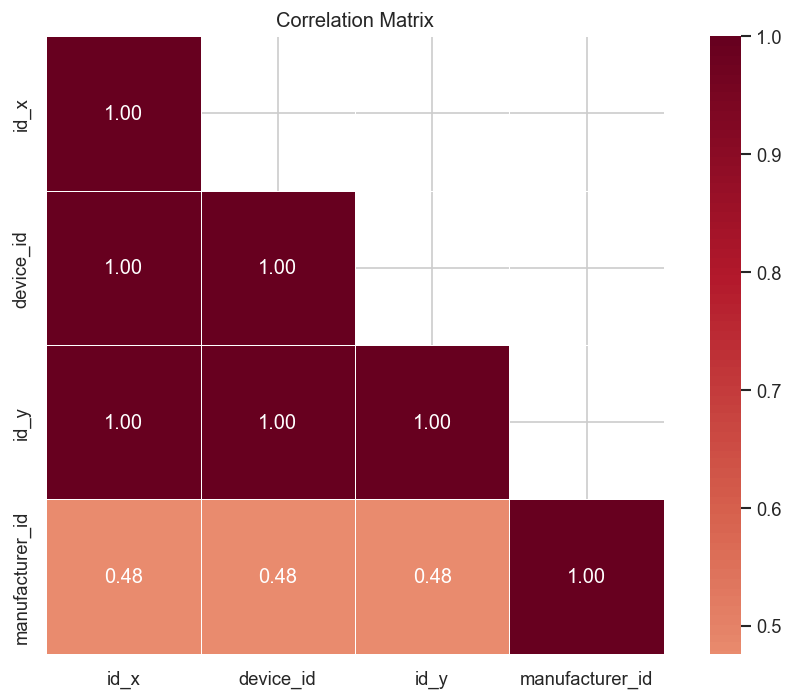

Top 10 strongest correlations:


  id_y  -  device_id: +1.0000
  id_x  -  device_id: +1.0000
  id_y  -  manufacturer_id: +0.4761
  id_x  -  manufacturer_id: +0.4760


In [22]:
if len(num_cols) >= 2:
    corr = merged_df[num_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    plt.figure(figsize=(max(8, len(num_cols) * 0.6), max(6, len(num_cols) * 0.5)))
    sns.heatmap(corr, mask=mask, annot=len(num_cols) <= 20,
                fmt=".2f", cmap="RdBu_r", center=0,
                square=True, linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    corr_unstacked = corr.unstack()
    corr_unstacked = corr_unstacked[
        corr_unstacked.index.get_level_values(0) !=
        corr_unstacked.index.get_level_values(1)
    ]
    top_corr = corr_unstacked.abs().sort_values(ascending=False).drop_duplicates().head(10)
    print("Top 10 strongest correlations:")
    for (col1, col2), val in top_corr.items():
        print(f"  {col1}  -  {col2}: {corr.loc[col1, col2]:+.4f}")

## 10. Summary

In [23]:
print("=" * 60)
print("EDA SUMMARY")
print("=" * 60)

print(f"\nDataset: {file_path.name}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"Missing cells: {df.isna().sum().sum():,} / {df.size:,} ({df.isna().sum().sum() / df.size * 100:.2f}%)")
print(f"Rows with >= 1 null: {(df.isna().sum(axis=1) >= 1).sum():,}")
print(f"Columns with >40% nulls: {(df.isna().mean() * 100 > 40).sum()}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"\nAfter cleaning:")
print(f"  Rows: {df_clean.shape[0]:,}  |  Columns: {df_clean.shape[1]}")
print(f"\nAfter merge with devices:")
print(f"  Rows: {merged_df.shape[0]:,}  |  Columns: {merged_df.shape[1]}")
print(f"  Numerical: {len(num_cols)}  |  Categorical: {len(cat_cols)}")
print(f"  Memory: {merged_df.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MB")

EDA SUMMARY

Dataset: events-1681209680.csv
Dimensions: 124,969 rows x 30 columns
Missing cells: 1,576,689 / 3,749,070 (42.06%)


Rows with >= 1 null: 124,969
Columns with >40% nulls: 17


Duplicate rows: 0

After cleaning:
  Rows: 39,520  |  Columns: 15

After merge with devices:
  Rows: 32,224  |  Columns: 27
  Numerical: 4  |  Categorical: 23
  Memory: 94.09 MB


In [24]:
pathtosave = Path(f'{proc_dir}/mergedDevicesEvents.csv')

In [25]:
merged_df.to_csv(pathtosave, index=False)
print(f"Saved: {pathtosave}  ({merged_df.shape[0]:,} rows x {merged_df.shape[1]:,} columns)")


Saved: D:\projects\dataScienceProjects\medicalSupply\data\processed\mergedDevicesEvents.csv  (32,224 rows x 27 columns)


---

## Part 3 ? Pre-cleaning

# 02. Data Pre-Cleaning - `events`

Aplica a `events` las decisiones anotadas en `AnotationsEDA.ipynb` (sección 2) y guarda el resultado en
`data/processed/eventsProcessed.csv`, entrada del pipeline del dashboard (`python -m src.pipeline`).

Orden de las reglas (idéntico al usado en `01_eda.ipynb` para que ambos notebooks produzcan el mismo resultado):

1. Se eliminan las 11 columnas descartadas en el EDA (enlaces, fechas casi vacías, texto no usado).
2. Se conservan las filas con **al menos 15 valores no nulos** sobre las 19 columnas restantes.
3. Se elimina `date` (99,6% de nulos incluso después del filtro).
4. Se eliminan las 3 columnas de texto anotadas como no usadas (`documents`, `action_summary`, `action_classification`).
5. Limpieza de strings, optimización a `category`, deduplicado y guardado.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("events")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
n_row0, n_col0 = df.shape
print(f"Loaded: {file_path.name}  ({n_row0:,} rows x {n_col0:,} cols)")

Loaded: events-1681209680.csv  (124,969 rows x 30 cols)


## 1. Columnas descartadas por decisión de análisis

Las 11 columnas descartadas en el EDA formal, con su % de nulos sobre los 124.969 registros crudos:

| Columna | % nulos | Motivo |
| :--- | ---: | :--- |
| `date_updated` | 99.82 | casi vacía |
| `target_audience` | 99.65 | casi vacía |
| `action_level` | 98.03 | casi vacía |
| `create_date` | 95.84 | casi vacía |
| `date_terminated` | 74.80 | casi vacía |
| `status` | 70.77 | casi vacía |
| `data_notes` | 53.65 | más de la mitad vacía |
| `date_posted` | 64.64 | casi vacía |
| `url` | 19.78 | redirige con HTTP 302, sin datos utilizables |
| `authorities_link` | 0.07 | enlace, no se usa en el análisis |
| `updated_at` | 0.00 | idéntica a `created_at` (100%) |

> Nota: `action` (50,00%), `reason` (47,45%) y `determined_cause` (71,34%) superan el umbral de 40% **pero se
> conservan**: son el motivo del recall y se recuperan casi por completo con el filtro de filas del paso 2.

In [2]:
columns_to_drop = [
    "url",              # HTTP 302, sin datos utilizables
    "updated_at",       # idéntica a created_at (100%)
    "target_audience",  # 99.65% nulos
    "authorities_link", # enlace, no usado
    "data_notes",       # 53.65% nulos
    "date_posted",      # 64.64% nulos
    "date_terminated",  # 74.80% nulos
    "status",           # 70.77% nulos
    "date_updated",     # 99.82% nulos
    "action_level",     # 98.03% nulos
    "create_date",      # 95.84% nulos
]
df.drop(columns=columns_to_drop, inplace=True)
print(f"Dropped {len(columns_to_drop)} column(s)")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

Dropped 11 column(s)
Shape: 124,969 rows x 19 columns


## 2. Filtro de filas

Se mantiene cada fila si tiene **al menos 15 de los 19 valores no nulos** restantes. Es el mismo umbral que
aplicó el EDA formal (`01_eda.ipynb`), de modo que `eventsProcessed.csv` y `mergedDevicesEvents.csv` contienen
los mismos registros.

In [3]:
n_raw = len(df)
df = df.dropna(thresh=15)
n_after_filter = len(df)
print(f"Rows kept: {n_after_filter:,} / {n_raw:,} ({n_after_filter/n_raw*100:.1f}%)")

nulls_left = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
print("\nNulls remaining per column (%):")
print(nulls_left[nulls_left > 0].to_string())

Rows kept: 39,520 / 124,969 (31.6%)

Nulls remaining per column (%):
date                      99.63
documents                 99.63
action_summary            90.99
determined_cause           9.37
number                     9.01
date_initiated_by_firm     2.46
action                     0.76
action_classification      0.37
reason                     0.07


## 3. Columna `date`

Sólo el 0,4% de las filas sobrevive con esta columna informada (99,6% de nulos tras el filtro) y no aporta al
análisis: se elimina. La referencia temporal del análisis es `date_initiated_by_firm`.

In [4]:
df.drop(columns=["date"], inplace=True)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

Shape: 39,520 rows x 18 columns


## 4. Columnas de texto anotadas como no usadas

Según `AnotationsEDA.ipynb`: `documents`, `action_summary` y `action_classification` no se usan en el análisis
(enlaces y texto libre). Sus valores nulos tras el filtro son 99,63%, 90,99% y 0,37%.

In [5]:
extra_drops = ["documents", "action_summary", "action_classification"]
df.drop(columns=extra_drops, inplace=True)
print(f"Dropped {len(extra_drops)} annotated column(s): {extra_drops}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

Dropped 3 annotated column(s): ['documents', 'action_summary', 'action_classification']
Shape: 39,520 rows x 15 columns


## 5. String cleaning

Se recortan espacios sobrantes en todas las columnas de texto.

In [6]:
str_cols = df.select_dtypes(include=["object"]).columns
for col in str_cols:
    df[col] = df[col].astype(str).str.strip().replace("nan", None)
print(f"Cleaned {len(str_cols)} string column(s)")

Cleaned 13 string column(s)


## 6. Type conversion

`date_initiated_by_firm` es la única fecha utilizable (1997-2018): se convierte a `datetime`.

In [7]:
df["date_initiated_by_firm"] = pd.to_datetime(df["date_initiated_by_firm"], errors="coerce")
parsed = df["date_initiated_by_firm"].notna().sum()
print(f"Parsed date_initiated_by_firm: {parsed:,}/{len(df):,} ({parsed/len(df)*100:.1f}%)")
print(f"Range: {df['date_initiated_by_firm'].min().date()} -> {df['date_initiated_by_firm'].max().date()}")

cat_opt = []
for col in df.select_dtypes(include=["object"]).columns:
    if df[col].nunique() / len(df) < 0.05:
        df[col] = df[col].astype("category")
        cat_opt.append(col)
print(f"Optimized to category: {cat_opt}")

Parsed date_initiated_by_firm: 38,547/39,520 (97.5%)
Range: 1997-06-01 -> 2018-07-09


Optimized to category: ['country', 'determined_cause', 'icij_notes', 'source', 'type']


## 7. Deduplicate rows

In [8]:
n_before = len(df)
df.drop_duplicates(inplace=True)
n_dupes = n_before - len(df)
print(f"Removed {n_dupes:,} duplicate row(s) ({n_dupes/n_before*100:.2f}%)")

Removed 0 duplicate row(s) (0.00%)


## 8. Save pre-cleaned data

In [9]:
out_path = proc_dir / "eventsProcessed.csv"
df.to_csv(out_path, index=False, encoding="utf-8")
print(f"Saved: {out_path}  ({df.shape[0]:,} rows x {df.shape[1]:,} columns)")

Saved: D:\projects\dataScienceProjects\medicalSupply\data\processed\eventsProcessed.csv  (39,520 rows x 15 columns)


## 9. Pre-cleaning Report

In [10]:
n_row1, n_col1 = df.shape
print("=" * 55)
print("  PRE-CLEANING REPORT (events)")
print("=" * 55)
print(f"  Original shape:           {n_row0:>8,} rows x {n_col0:,} cols")
print(f"  Final shape:              {n_row1:>8,} rows x {n_col1:,} cols")
print(f"  Rows dropped (<15 values):{n_row0 - n_after_filter:>8,}")
print(f"  Columns dropped:          {n_col0 - n_col1:>8}")
print(f"    - Decisión de análisis:  {len(columns_to_drop):>8}")
print(f"    - date:                  {1:>8}")
print(f"    - Texto anotado:         {len(extra_drops):>8}")
print(f"  Duplicates removed:       {n_dupes:>8}")
print(f"  Dates parsed:             {1:>8}")
print(f"  Optimized to category:    {len(cat_opt):>8}")
print(f"  Remaining missing:        {df.isna().sum().sum():>8,}")

  PRE-CLEANING REPORT (events)
  Original shape:            124,969 rows x 30 cols
  Final shape:                39,520 rows x 15 cols
  Rows dropped (<15 values):  85,449
  Columns dropped:                15
    - Decisión de análisis:        11
    - date:                         1
    - Texto anotado:                3
  Duplicates removed:              0
  Dates parsed:                    1
  Optimized to category:           5
  Remaining missing:           8,564
